In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tkinter import Tk, filedialog

In [2]:

def get_file_path():
    root = Tk()
    root.withdraw() 
    file_path = filedialog.askopenfilename(title="Select CSV file", filetypes=[("CSV files", "*.csv")])
    root.destroy()  
    return file_path


def load_and_preprocess_data(file_path):
    data = pd.read_csv(file_path)
    data.replace('..', pd.NA, inplace=True)
    year_columns = [col for col in data.columns if 'YR' in col]
    for col in year_columns:
        data[col] = pd.to_numeric(data[col], errors='coerce')

    return data


def handle_missing_values(df):
    numeric_columns = df.select_dtypes(include=[np.number]).columns
    df[numeric_columns] = df[numeric_columns].fillna(df[numeric_columns].mean())
    return df


In [3]:

def reshape_data_for_trend(df, trend_type):
    trend_df = df[df['Series Name'].str.contains(trend_type, case=False, na=False)]

    reshaped_df = trend_df.melt(id_vars=['Country Name', 'Series Name', 'Series Code'],
                                value_vars=[col for col in trend_df.columns if 'YR' in col],
                                var_name='Year', value_name='Value')

    reshaped_df['Year'] = reshaped_df['Year'].str[:4].astype(int)
    reshaped_df.sort_values(by=['Country Name', 'Year'], inplace=True)

    reshaped_df['Value'] = pd.to_numeric(reshaped_df['Value'], errors='coerce')

    return reshaped_df


def plot_overall_trend(df, trend_type):
    trend_df = df.dropna(subset=['Year', 'Value'])  


    mean_trend = trend_df.groupby('Year')['Value'].mean().reset_index()

    if len(mean_trend) > 1:
        years = mean_trend['Year'].values.reshape(-1, 1)
        values = mean_trend['Value'].values.reshape(-1, 1)


        model = LinearRegression()
        model.fit(years, values)
        slope = model.coef_[0][0]
        intercept = model.intercept_[0]

        line_space = np.linspace(years.min(), years.max(), 100).reshape(-1, 1)

        plt.figure(figsize=(12, 6))
        plt.scatter(years, values, label=f'Average {trend_type} % per Year', color='blue')
        plt.plot(line_space, model.predict(line_space), color='red', label=f'Linear Trend (y = {slope:.2f}x + {intercept:.2f})')
        plt.title(f'Overall {trend_type} Percentage Trend with Regression Line')
        plt.ylabel('Average Percentage')
        plt.xlabel('Year')
        plt.legend()
        plt.show()
    else:
        print(f"Not enough data to plot the overall trend for {trend_type}.")


In [4]:

def get_top_countries(df, series_name_contains, top_n=5):
    filtered_df = df[df['Series Name'].str.contains(series_name_contains, case=False, na=False)]

    mean_values = filtered_df.groupby('Country Name')['Value'].mean()
    top_countries = mean_values.nlargest(top_n).index
    return top_countries


def plot_top_countries(df, series_name_contains, title):
    top_countries = get_top_countries(df, series_name_contains)
    filtered_df = df[(df['Country Name'].isin(top_countries)) & (df['Series Name'].str.contains(series_name_contains))]
    plt.figure(figsize=(15, 7))
    for country in top_countries:
        country_data = filtered_df[filtered_df['Country Name'] == country]
        plt.plot(country_data['Year'], country_data['Value'], label=country)
    plt.title(title)
    plt.xlabel('Year')
    plt.ylabel(f'{series_name_contains.capitalize()} Percentage')
    plt.xticks(rotation=45)
    plt.gca().xaxis.set_major_locator(ticker.MultipleLocator(1))
    plt.legend()
    plt.grid(True)
    plt.show()


In [5]:

def prepare_data_for_lstm(df, column, n_steps):
    data = df[column].values.reshape(-1, 1)
    scaler = MinMaxScaler(feature_range=(0, 1))
    data_normalized = scaler.fit_transform(data)
    X, y = [], []
    for i in range(n_steps, len(data_normalized)):
        X.append(data_normalized[i - n_steps:i, 0])
        y.append(data_normalized[i, 0])
    X, y = np.array(X), np.array(y)
    X = X.reshape(X.shape[0], X.shape[1], 1)
    return X, y, scaler

def train_lstm_model(X, y, epochs=25):
    model = Sequential([
        LSTM(100, activation='relu', return_sequences=True, input_shape=(X.shape[1], 1)),
        LSTM(100, activation='relu'),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mean_squared_error')
    model.fit(X, y, epochs=epochs, batch_size=32, verbose=2)
    return model


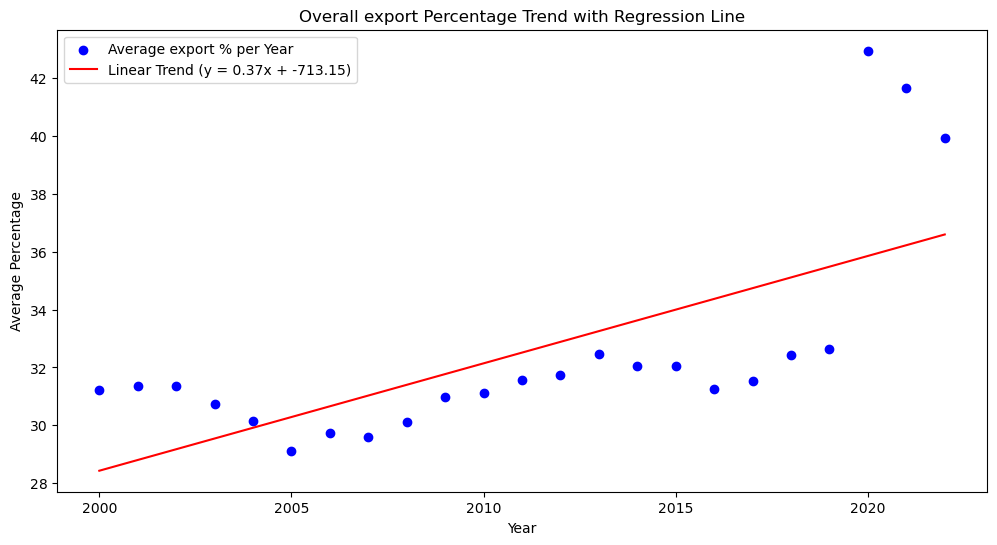

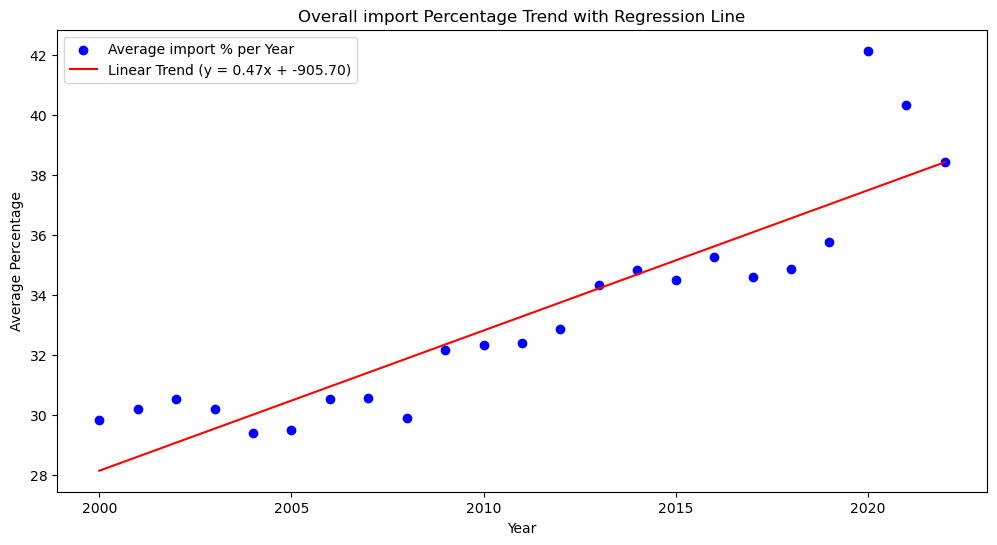

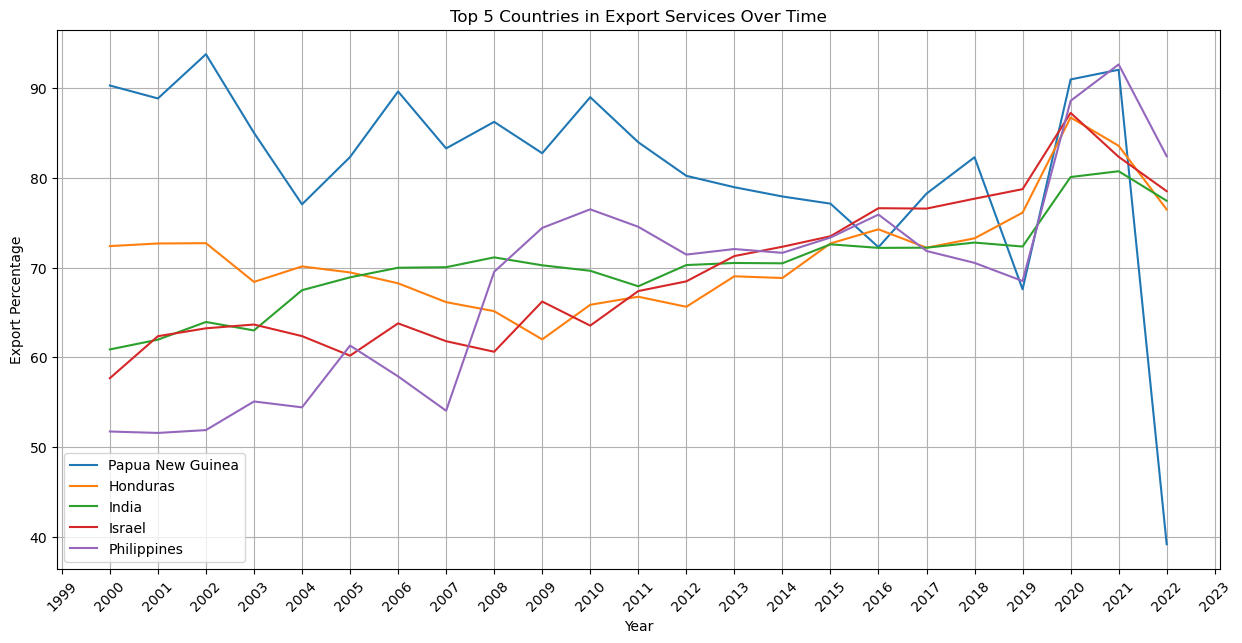

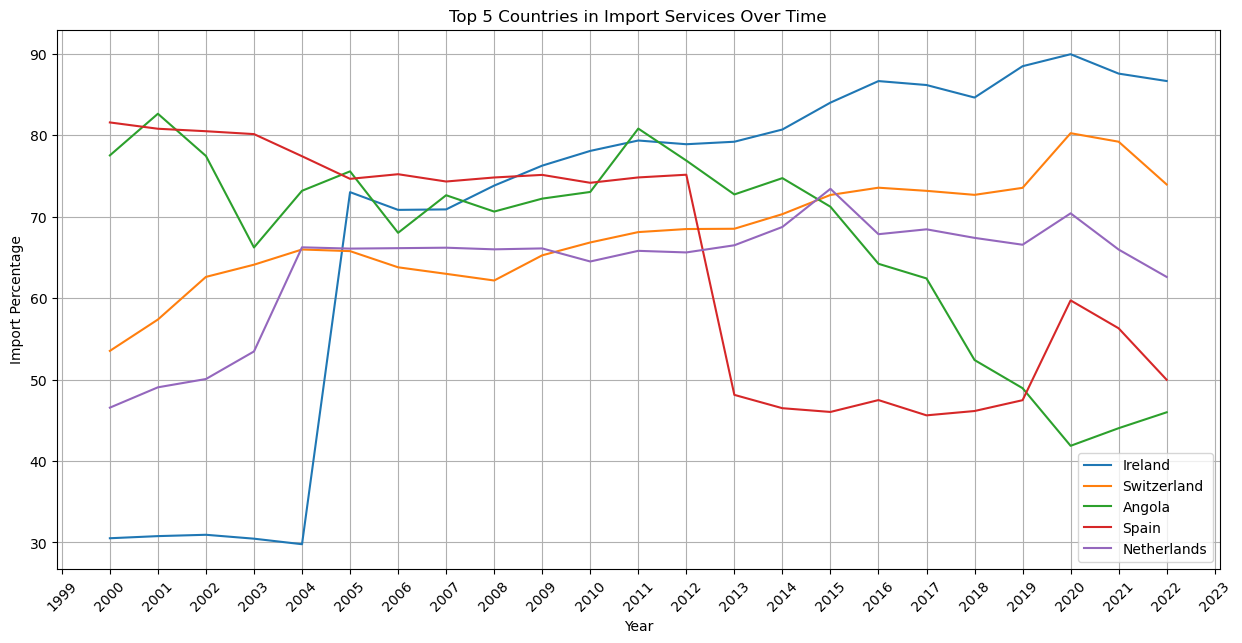

In [7]:

file_path = "import export of all countries.csv"

df = load_and_preprocess_data(file_path)


df = handle_missing_values(df)

export_df = reshape_data_for_trend(df, 'export')
import_df = reshape_data_for_trend(df, 'import')

plot_overall_trend(export_df, 'export')
plot_overall_trend(import_df, 'import')

plot_top_countries(export_df, 'export', 'Top 5 Countries in Export Services Over Time')
plot_top_countries(import_df, 'import', 'Top 5 Countries in Import Services Over Time')


In [8]:
n_steps = 3
X, y, scaler = prepare_data_for_lstm(export_df, 'Value', n_steps)

model = train_lstm_model(X, y, epochs=50)

n_future = 5  
forecast_input = X[-1:, :].copy() 
forecast_values = []


Epoch 1/50


C:\Users\pantech\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


192/192 - 5s - 27ms/step - loss: 0.0312
Epoch 2/50
192/192 - 1s - 7ms/step - loss: 0.0095
Epoch 3/50
192/192 - 2s - 8ms/step - loss: 0.0086
Epoch 4/50
192/192 - 1s - 8ms/step - loss: 0.0072
Epoch 5/50
192/192 - 1s - 7ms/step - loss: 0.0066
Epoch 6/50
192/192 - 1s - 7ms/step - loss: 0.0061
Epoch 7/50
192/192 - 2s - 9ms/step - loss: 0.0061
Epoch 8/50
192/192 - 1s - 6ms/step - loss: 0.0058
Epoch 9/50
192/192 - 1s - 7ms/step - loss: 0.0059
Epoch 10/50
192/192 - 1s - 6ms/step - loss: 0.0058
Epoch 11/50
192/192 - 1s - 7ms/step - loss: 0.0059
Epoch 12/50
192/192 - 2s - 13ms/step - loss: 0.0058
Epoch 13/50
192/192 - 1s - 6ms/step - loss: 0.0058
Epoch 14/50
192/192 - 1s - 7ms/step - loss: 0.0058
Epoch 15/50
192/192 - 1s - 7ms/step - loss: 0.0058
Epoch 16/50
192/192 - 1s - 7ms/step - loss: 0.0058
Epoch 17/50
192/192 - 1s - 6ms/step - loss: 0.0058
Epoch 18/50
192/192 - 1s - 6ms/step - loss: 0.0058
Epoch 19/50
192/192 - 1s - 6ms/step - loss: 0.0058
Epoch 20/50
192/192 - 2s - 8ms/step - loss: 0.005

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 401ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


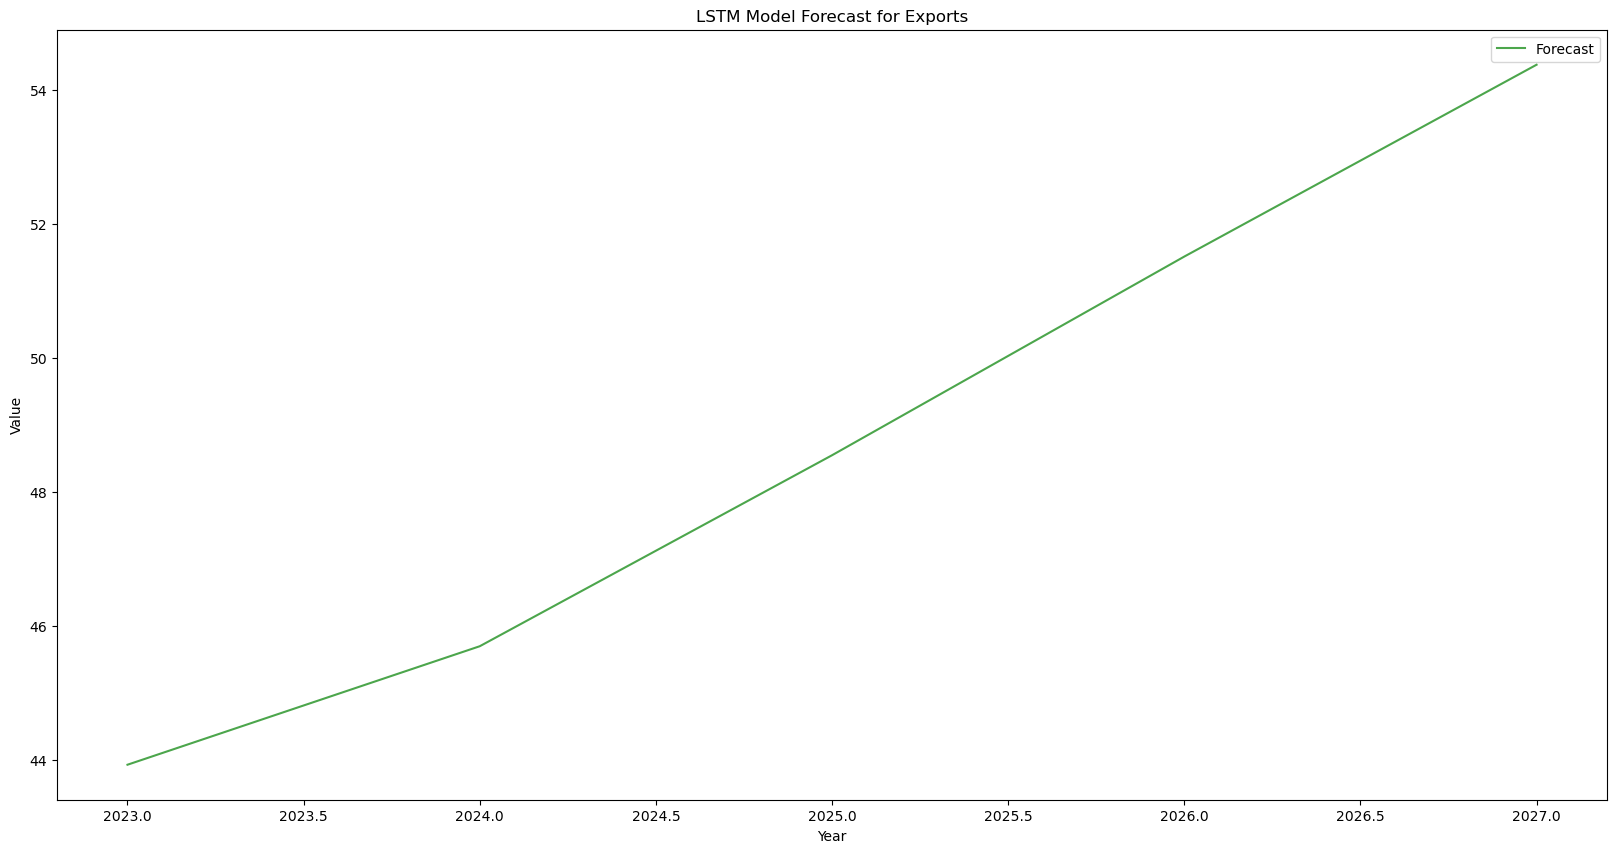

In [9]:



for _ in range(n_future):
    forecast_value = model.predict(forecast_input)
    forecast_values.append(forecast_value[0, 0])
    forecast_input = np.roll(forecast_input, shift=-1, axis=1)
    forecast_input[0, -1] = forecast_value[0, 0]

forecast_values = scaler.inverse_transform(np.array(forecast_values).reshape(-1, 1))

forecast_years = np.arange(export_df['Year'].max() + 1, export_df['Year'].max() + 1 + n_future)
plt.figure(figsize=(20, 10))
plt.plot(forecast_years, forecast_values, label='Forecast', color='green', alpha=0.7)
plt.title('LSTM Model Forecast for Exports')
plt.xlabel('Year')
plt.ylabel('Value')
plt.legend()
plt.show()




In [10]:
import seaborn as sns

n_future = 5  

forecast_df = pd.DataFrame(index=range(n_future), columns=export_df['Country Name'].unique())

for country in export_df['Country Name'].unique():

    country_data = export_df.loc[export_df['Country Name'] == country, 'Value'].values
    if len(country_data) < n_steps:

        continue

    X_country, _, scaler_country = prepare_data_for_lstm(pd.DataFrame({'Value': country_data}), 'Value', n_steps)

    forecast_input = X_country[-1:, :].copy()  
    forecast_values = []

    for _ in range(n_future):
        forecast_value = model.predict(forecast_input)
        forecast_values.append(forecast_value[0, 0])
        forecast_input = np.roll(forecast_input, shift=-1, axis=1)
        forecast_input[0, -1] = forecast_value[0, 0]

    forecast_values = scaler_country.inverse_transform(np.array(forecast_values).reshape(-1, 1))

    forecast_df[country] = forecast_values.flatten()

plt.figure(figsize=(20, 10))
for country in forecast_df.columns:
    sns.kdeplot(forecast_df[country], label=country, shade=True)

plt.title('LSTM Model Forecast for Exports - Country Wise (KDE Plot)')
plt.xlabel('Forecasted Value')
plt.ylabel('Density')
plt.legend()
plt.show()



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━

KeyboardInterrupt: 

In [ ]:

plt.figure(figsize=(20, 10))

for country in forecast_df.columns:

    country_data = forecast_df[country].dropna().values


    years = range(export_df['Year'].max() + 1, export_df['Year'].max() + 1 + n_future)


    plt.bar(years, country_data, alpha=0.7, label=country)

plt.title('Forecasted Values Over Years - Country Wise')
plt.xlabel('Year')
plt.ylabel('Value')
plt.legend()
plt.show()



In [ ]:
import pickle

with open('lstm_model.pkl', 'wb') as file:
    pickle.dump(model, file)